In [1]:
pip install pandas numpy matplotlib scikit-learn imbalanced-learn


   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# LAB 09 — Bias, Variance and Imbalanced Data
## Student Information
Name: JOT SACHDEV

Student ID:023-24-0168

Section:F
GitHub:


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42

In [4]:
df = pd.read_csv("healthcare-dataset-stroke-data_1.csv")

print("Shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nGender value counts:")
print(df["gender"].value_counts())

counts = df["stroke"].value_counts()
pct = df["stroke"].value_counts(normalize=True) * 100
print("\nStroke = 0:", counts[0], f"({pct[0]:.2f}%)")
print("Stroke = 1:", counts[1], f"({pct[1]:.2f}%)")

Shape: (5110, 12)

Missing values:
bmi    201
dtype: int64

Gender value counts:
gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Stroke = 0: 4861 (95.13%)
Stroke = 1: 249 (4.87%)


In [5]:

df = df.drop(columns=["id"])
df = df[df["gender"] != "Other"].reset_index(drop=True)
df = pd.get_dummies(df, drop_first=True)

print(df.shape)
df.head()

(5109, 16)


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.6,1,True,True,False,True,False,False,True,True,False,False
1,61.0,0,0,202.21,NaN,1,False,True,False,False,True,False,False,False,True,False
2,80.0,0,1,105.92,32.5,1,True,True,False,True,False,False,False,False,True,False
3,49.0,0,0,171.23,34.4,1,False,True,False,True,False,False,True,False,False,True
4,79.0,1,0,174.12,24.0,1,False,True,False,False,True,False,False,False,True,False


In [6]:
X = df.drop(columns=["stroke"])
y = df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
bmi_median = X_train["bmi"].median()
X_train["bmi"] = X_train["bmi"].fillna(bmi_median)
X_test["bmi"]  = X_test["bmi"].fillna(bmi_median)   

scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train),
                         columns=X_train.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),
                         columns=X_test.columns, index=X_test.index)

In [7]:
print("Train size:", X_train.shape, "| Test size:", X_test.shape)
print("Strokes in TRAIN:", y_train.sum(), f"({y_train.mean()*100:.2f}%)")
print("Strokes in TEST :", y_test.sum(),  f"({y_test.mean()*100:.2f}%)")

Train size: (4087, 15) | Test size: (1022, 15)
Strokes in TRAIN: 199 (4.87%)
Strokes in TEST : 50 (4.89%)


**Answer (a):**
The data is very imbalanced. Only 249 out of 5,109 patients (about 4.9%) had a stroke. The other 95% did not.
We used `stratify=y` so that the train set and the test set both keep the same stroke ratio (199 strokes in train, 50 in test). Without it, a random split could put too few strokes in the test set.
If the test set has only a few stroke cases, metrics like recall and precision become unstable. One patient more or less can change the result a lot, so we cannot trust the score.

Part 1: The Accuracy Trap

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay)

In [9]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    """Fit model on train, return 6 metrics on test."""
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {
        "Accuracy":  accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall":    recall_score(y_te, pred),
        "F1":        f1_score(y_te, pred, zero_division=0),
        "ROC AUC":   roc_auc_score(y_te, proba),
        "PR AUC":    average_precision_score(y_te, proba),
    }

In [10]:
dummy = DummyClassifier(strategy="most_frequent")
res_dummy = evaluate(dummy, X_train, y_train, X_test, y_test)
print("Baseline accuracy:", round(res_dummy["Accuracy"], 4))

Baseline accuracy: 0.9511


           Dummy (majority)  Logistic Regression
Accuracy             0.9511               0.9521
Precision            0.0000               1.0000
Recall               0.0000               0.0200
F1                   0.0000               0.0392
ROC AUC              0.5000               0.8394
PR AUC               0.0489               0.2692


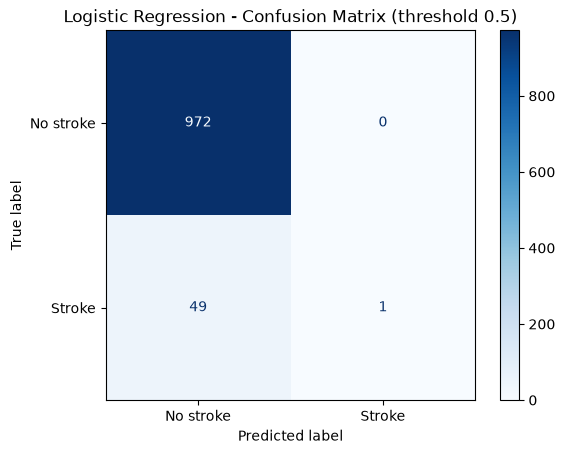

[[972   0]
 [ 49   1]]


In [11]:
lr = LogisticRegression(random_state=SEED, max_iter=1000)
res_lr = evaluate(lr, X_train_s, y_train, X_test_s, y_test)

results = pd.DataFrame({"Dummy (majority)": res_dummy,
                        "Logistic Regression": res_lr}).round(4)
print(results)

# confusion matrix
pred_lr = lr.predict(X_test_s)
cm = confusion_matrix(y_test, pred_lr)
ConfusionMatrixDisplay(cm, display_labels=["No stroke", "Stroke"]).plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix (threshold 0.5)")
plt.show()
print(cm)

**Answer (b):**
The confusion matrix shows 972 true negatives, 0 false positives, 49 false negatives and only 1 true positive. There are 50 stroke patients in the test set, but the model found just 1 of them. So Recall is only 0.02 (2%).

A false negative means a patient who really has a stroke risk is told "you are fine". This patient gets no treatment and no follow-up, which can be very dangerous. In a hospital this is the worst kind of mistake.

We should not trust accuracy (0.9521), because it is high only since 95% of patients are healthy. Instead we should trust:
- Recall (0.02): it shows we miss almost all strokes.
- F1 (0.0392): it is very low, so the model is weak overall.
- ROC AUC (0.8394) and PR AUC (0.2692): they judge the model's probability scores, not just one threshold.

Precision is 1.0, but it comes from only 1 predicted stroke, so it is not reliable.

Part 2 — Underfitting, Overfitting, Bias and Variance 


In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

In [13]:
depths = list(range(1, 16)) + [None]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

train_auc, cv_auc = [], []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    tree.fit(X_train, y_train)
    train_auc.append(roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]))

    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=d, random_state=SEED),
        X_train, y_train, cv=cv, scoring="roc_auc"
    )
    cv_auc.append(scores.mean())

vc = pd.DataFrame({"max_depth": [str(d) for d in depths],
                   "Train AUC": train_auc, "CV AUC": cv_auc}).round(4)
print(vc)

best_idx = int(np.argmax(cv_auc))
print("\nBest depth by CV AUC:", depths[best_idx], "| CV AUC =", round(cv_auc[best_idx], 4))

   max_depth  Train AUC  CV AUC
0          1     0.7171  0.7317
1          2     0.8208  0.8168
2          3     0.8375  0.8161
3          4     0.8580  0.8180
4          5     0.8758  0.7921
5          6     0.9026  0.7585
6          7     0.9276  0.7385
7          8     0.9494  0.7138
8          9     0.9678  0.6812
9         10     0.9808  0.6414
10        11     0.9910  0.6108
11        12     0.9959  0.6126
12        13     0.9985  0.5955
13        14     0.9996  0.5889
14        15     0.9999  0.5779
15      None     1.0000  0.5644

Best depth by CV AUC: 4 | CV AUC = 0.818


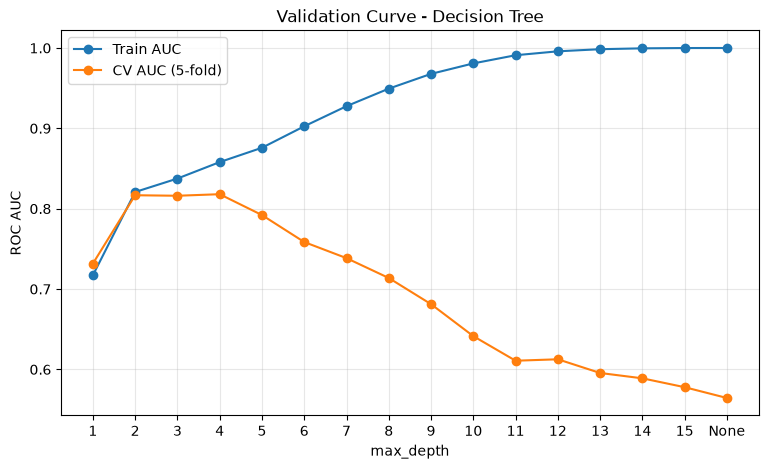

In [14]:
labels = [str(d) for d in depths]

plt.figure(figsize=(9, 5))
plt.plot(labels, train_auc, marker="o", label="Train AUC")
plt.plot(labels, cv_auc, marker="o", label="CV AUC (5-fold)")
plt.xlabel("max_depth")
plt.ylabel("ROC AUC")
plt.title("Validation Curve - Decision Tree")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Answer (a):**
- Underfitting (depth 1): Train AUC = 0.7171 and CV AUC = 0.7317. Both scores are low and almost equal. The tree is too simple (high bias), so it cannot learn the pattern.
- Best zone (depth 2 to 4): At depth 3, Train AUC = 0.8375 and CV AUC = 0.8161. Both are high and close to each other, so the model learns well and also works on new data.
- Overfitting (depth 5 and above, worst at None): From depth 5 the CV AUC keeps falling (0.7921 at depth 5) while the train AUC keeps rising. At depth None, Train AUC = 1.0000 but CV AUC = 0.5644. The tree memorizes the training data (high variance), and the gap between train and CV is huge. CV AUC is close to random guessing (0.5).

I would choose depth 4, because it has the best CV AUC (0.8180). Depth 3 (0.8161) is almost the same and a bit simpler, so it is also a good choice.

In [15]:
n_boot = 40
depth_list = [1, 3, None]
rows = []

for d in depth_list:
    rng = np.random.default_rng(SEED)      # har depth ke liye same random samples
    probs = np.zeros((n_boot, len(X_test)))   # shape (40, test patients)
    single_aucs = []

    for i in range(n_boot):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        tree = DecisionTreeClassifier(max_depth=d, random_state=SEED)
        tree.fit(X_train.iloc[idx], y_train.iloc[idx])
        probs[i] = tree.predict_proba(X_test)[:, 1]
        single_aucs.append(roc_auc_score(y_test, probs[i]))

    mean_var = probs.var(axis=0).mean()                 # har patient ka variance, phir average
    mean_single_auc = np.mean(single_aucs)               # 40 trees ka average AUC
    avg_pred_auc = roc_auc_score(y_test, probs.mean(axis=0))  # averaged prediction ka AUC

    rows.append({"max_depth": str(d),
                 "Mean variance": mean_var,
                 "Mean test AUC (single tree)": mean_single_auc,
                 "AUC of averaged prediction": avg_pred_auc})

var_table = pd.DataFrame(rows).round(5)
print(var_table)

  max_depth  Mean variance  Mean test AUC (single tree)  \
0         1        0.00068                      0.76234   
1         3        0.00185                      0.79300   
2      None        0.04370                      0.55535   

   AUC of averaged prediction  
0                     0.81317  
1                     0.83508  
2                     0.74288  


**Answer (c):**
Variance goes up a lot with depth. The mean variance is 0.00068 at depth 1, 0.00185 at depth 3 and 0.0437 at depth None. The full tree has about 64 times more variance than depth 1. This means a deep tree changes its predictions a lot when the training data changes a little.

Averaging 40 trees improves the AUC for every depth: from 0.7623 to 0.8132 (depth 1), from 0.7930 to 0.8351 (depth 3) and from 0.5554 to 0.7429 (depth None). The biggest gain is for depth None (+0.19), because it has the most variance, and averaging cancels out random errors.

This is what a Random Forest does: it trains many deep trees on bootstrap samples and averages them. Each tree has high variance, but the average has much lower variance, so the forest is more stable and more accurate than a single tree.

**Answer (d):**
The bias-variance trade-off means: a simple model has high bias (it misses the pattern) but low variance (it is stable), and a complex model has low bias (it fits the training data well) but high variance (it changes a lot with new data). We need a balance in the middle.
- Depth 1: high bias, low variance (variance 0.00068, AUC only 0.76). It underfits.
- Depth 3: balanced. Low variance (0.00185) and the best single-tree AUC (0.7930). It is the sweet spot.
- Depth None: low bias but very high variance (0.0437, AUC 0.5554). It overfits.

Part 3: ROC, AUC, Precision-Recall aur Threshold

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.model_selection import cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, precision_recall_curve

In [19]:
models = {
    "Logistic Regression": (LogisticRegression(random_state=SEED, max_iter=1000), X_train_s, X_test_s),
    "Decision Tree (depth 3)": (DecisionTreeClassifier(max_depth=3, random_state=SEED), X_train, X_test),
    "Random Forest": (RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED), X_train, X_test),
}

test_probs = {}
for name, (model, Xtr_, Xte_) in models.items():
    model.fit(Xtr_, y_train)
    test_probs[name] = model.predict_proba(Xte_)[:, 1]
    print(name, "| ROC AUC =", round(roc_auc_score(y_test, test_probs[name]), 4),
          "| PR AUC =", round(average_precision_score(y_test, test_probs[name]), 4))

Logistic Regression | ROC AUC = 0.8394 | PR AUC = 0.2692
Decision Tree (depth 3) | ROC AUC = 0.7956 | PR AUC = 0.1621
Random Forest | ROC AUC = 0.8224 | PR AUC = 0.2255


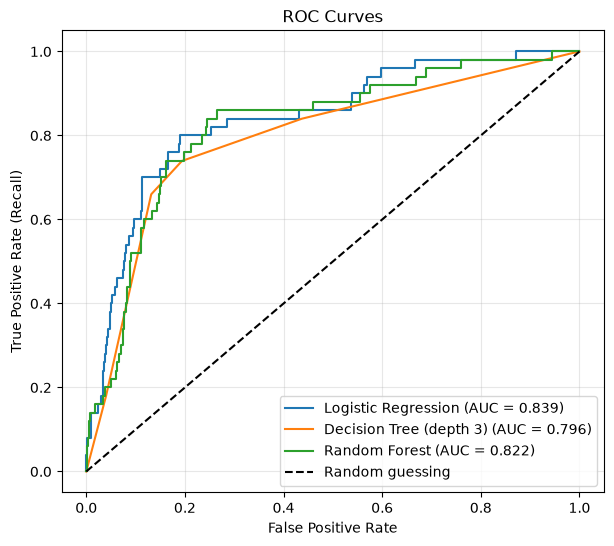

In [20]:
plt.figure(figsize=(7, 6))
for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

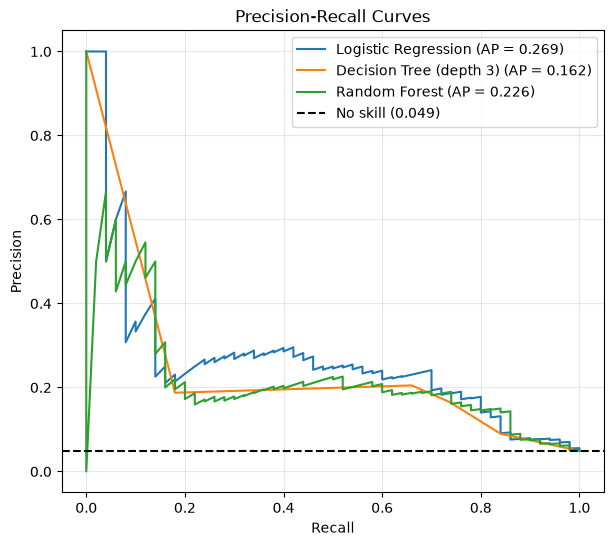

In [21]:
no_skill = y_test.mean()    # stroke rate

plt.figure(figsize=(7, 6))
for name, p in test_probs.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    plt.plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})")
plt.axhline(no_skill, color="k", linestyle="--", label=f"No skill ({no_skill:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

oof_probs = cross_val_predict(
    LogisticRegression(random_state=SEED, max_iter=1000),
    X_train_s, y_train, cv=cv, method="predict_proba"
)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_probs)

valid = thr[rec[:-1] >= 0.80]
chosen_thr = valid.max()     
print("Chosen threshold:", round(chosen_thr, 4))

Chosen threshold: 0.0509


Test Recall   : 0.82
Test Precision: 0.1349
Confusion matrix:
 [[709 263]
 [  9  41]]
Patients flagged: 304
False alarms (FP): 263
Missed strokes (FN): 9


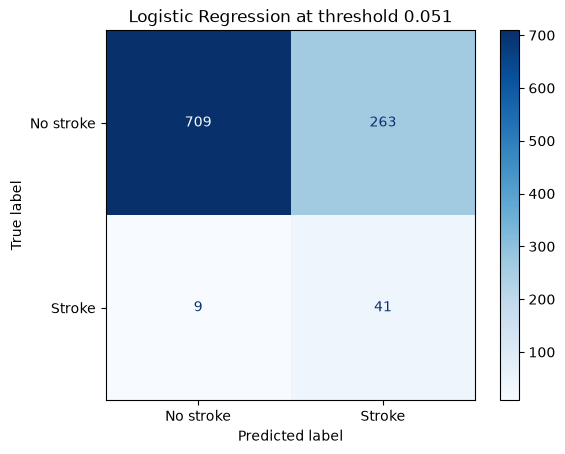

In [23]:
lr_final = LogisticRegression(random_state=SEED, max_iter=1000).fit(X_train_s, y_train)
test_p = lr_final.predict_proba(X_test_s)[:, 1]
pred_thr = (test_p >= chosen_thr).astype(int)

cm = confusion_matrix(y_test, pred_thr)
tn, fp, fn, tp = cm.ravel()

print("Test Recall   :", round(recall_score(y_test, pred_thr), 4))
print("Test Precision:", round(precision_score(y_test, pred_thr), 4))
print("Confusion matrix:\n", cm)
print("Patients flagged:", pred_thr.sum())
print("False alarms (FP):", fp)
print("Missed strokes (FN):", fn)

ConfusionMatrixDisplay(cm, display_labels=["No stroke", "Stroke"]).plot(cmap="Blues")
plt.title(f"Logistic Regression at threshold {chosen_thr:.3f}")
plt.show()

**Answer (a):**
Both can be true because recall and AUC measure different things. Recall depends on one fixed threshold (0.5). Because strokes are rare, the model's probabilities are small (most are below 0.5), so at 0.5 it flags almost nobody and recall is only 0.02.
ROC AUC does not use any single threshold. It checks how well the model ranks patients: how often a real stroke patient gets a higher probability than a healthy one. Logistic Regression has an AUC of 0.8394, so its ranking is good, but the 0.5 cut-off is in the wrong place. If we move the threshold lower, recall goes up.

**Answer (b):**
Precision-Recall is more informative here. The data is very imbalanced (no-skill line = 0.049). ROC curves look good (AUC 0.80 to 0.84) because the huge number of healthy patients keeps the False Positive Rate small, even when there are many false alarms. The PR curve shows the real problem: Logistic Regression has AP = 0.269, only about 5.5 times the no-skill line of 0.049, and the curves drop to low precision quickly. So PR shows how hard it is to find strokes without many false alarms.

**Answer (c):**
At the threshold 0.0509 the test recall is 0.82 (41 of 50 strokes caught, only 9 missed). The price: 304 patients are flagged but only 41 are real strokes, so 263 are false alarms and precision is only 0.135. That means about 7 out of 8 flagged patients are healthy.
For: This is acceptable for a screening test, because missing a stroke can cost a life, while a false alarm only means an extra check-up. Catching 82% of strokes is a big improvement over 2%.
Against: 263 false alarms (about 26% of all patients in the test set) means extra cost, work, worry and tests for healthy people. If the hospital has limited resources, this may be too much. A cheap second test after the flag could reduce the cost.

Part 4: Resampling aur SMOTE

In [24]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

In [25]:
def evaluate_full(model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {
        "Train rows": len(X_tr),
        "Train strokes": int(y_tr.sum()),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall":    recall_score(y_te, pred),
        "F1":        f1_score(y_te, pred, zero_division=0),
        "ROC AUC":   roc_auc_score(y_te, proba),
        "PR AUC":    average_precision_score(y_te, proba),
    }

def make_lr(cw=None):
    return LogisticRegression(random_state=SEED, max_iter=1000, class_weight=cw)

def make_rf(cw=None):
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                  random_state=SEED, class_weight=cw)

samplers = {
    "Undersampling": RandomUnderSampler(random_state=SEED),
    "Oversampling":  RandomOverSampler(random_state=SEED),
    "SMOTE":         SMOTE(random_state=SEED),
}

setups = [
    ("Logistic Regression", make_lr, X_train_s, X_test_s),   # scaled data
    ("Random Forest",       make_rf, X_train,   X_test),      # original data
]

rows = {}
for model_name, make, Xtr_, Xte_ in setups:
    rows[f"{model_name} | No resampling"] = evaluate_full(make(), Xtr_, y_train, Xte_, y_test)
    rows[f"{model_name} | class_weight=balanced"] = evaluate_full(make("balanced"), Xtr_, y_train, Xte_, y_test)
    for s_name, sampler in samplers.items():
        Xr, yr = sampler.fit_resample(Xtr_, y_train)          # sirf TRAIN
        rows[f"{model_name} | {s_name}"] = evaluate_full(make(), Xr, yr, Xte_, y_test)

compare = pd.DataFrame(rows).T
compare["Train rows"] = compare["Train rows"].astype(int)
compare["Train strokes"] = compare["Train strokes"].astype(int)
compare.round(4)

,Train rows,Train strokes,Precision,Recall,F1,ROC AUC,PR AUC
Logistic Regression | No resampling,4087,199,1.0000,0.02,0.0392,0.8394,0.2692
Logistic Regression | class_weight=balanced,4087,199,0.1347,0.80,0.2305,0.8395,0.2595
Logistic Regression | Undersampling,398,199,0.1246,0.82,0.2164,0.8352,0.2338
Logistic Regression | Oversampling,7776,3888,0.1333,0.80,0.2286,0.8385,0.2646
Logistic Regression | SMOTE,7776,3888,0.1338,0.80,0.2292,0.8406,0.2876
Random Forest | No resampling,4087,199,0.0000,0.00,0.0000,0.8224,0.2255
Random Forest | class_weight=balanced,4087,199,0.1895,0.72,0.3000,0.8150,0.1987
Random Forest | Undersampling,398,199,0.1050,0.84,0.1867,0.8203,0.2030
Random Forest | Oversampling,7776,3888,0.1882,0.32,0.2370,0.8111,0.1906
Random Forest | SMOTE,7776,3888,0.1628,0.28,0.2059,0.7814,0.1750


In [26]:

X_all = X.copy()
X_all["bmi"] = X_all["bmi"].fillna(X_all["bmi"].median())  

X_smote, y_smote = SMOTE(random_state=SEED).fit_resample(X_all, y)

Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(
    X_smote, y_smote, test_size=0.20, stratify=y_smote, random_state=SEED
)
wrong = evaluate_full(make_rf(), Xw_tr, yw_tr, Xw_te, yw_te)

correct = rows["Random Forest | SMOTE"]     

pd.DataFrame({"Wrong order (SMOTE then split)": wrong,
              "Correct order (split then SMOTE)": correct}).T.round(4)

,Train rows,Train strokes,Precision,Recall,F1,ROC AUC,PR AUC
Wrong order (SMOTE then split),7776.0,3888.0,0.9283,0.9455,0.9368,0.9848,0.9856
Correct order (split then SMOTE),7776.0,3888.0,0.1628,0.2800,0.2059,0.7814,0.1750


**Answer (a):**
What changed: Recall jumped from 0.02 to about 0.80-0.82 with every method (class_weight, undersampling, oversampling, SMOTE). Precision dropped from 1.0 (which came from only 1 prediction) to about 0.13, because the model now flags many patients and most are false alarms. F1 rose from 0.039 to about 0.22-0.23.
What did NOT change: ROC AUC stayed almost the same (0.8394 without resampling, between 0.835 and 0.841 with the methods). PR AUC also stayed in a similar range (0.23 to 0.29).
Why: Logistic Regression is a simple linear model. Rebalancing mostly shifts its probabilities up, which is like moving the decision threshold. It does not change how well the model ranks stroke patients above healthy ones, and AUC measures only the ranking. So the model is not smarter, it just flags more people.

**Answer (b):**
No, Random Forest reacted differently. SMOTE helped Logistic Regression (Recall 0.80, ROC AUC 0.8406) but hurt Random Forest: Recall was only 0.20 and ROC AUC fell from 0.8224 to 0.7668. Oversampling also gave low recall (0.32), while class_weight=balanced (Recall 0.72, F1 0.30) and undersampling (Recall 0.84) worked better.
A possible reason: a Random Forest has deep, flexible trees. With copied or synthetic stroke rows, the trees memorize those training points and learn a very specific pattern, so they do not recognize real new stroke patients. A simple linear model cannot memorize like that.

**Answer (c):**
The wrong-order numbers are very high (ROC AUC 0.9811, Precision 0.929, Recall 0.9424) compared with the correct order (ROC AUC 0.7668, Precision 0.1266, Recall 0.20). They cannot be trusted.
Reason: when SMOTE is done before the split, it creates synthetic patients by mixing real stroke patients. After the split, a real patient may be in the train set while its synthetic "twin" (a nearly identical new row) is in the test set. So information leaks from the training data into the test data, and the model is tested on rows that look almost the same as ones it has already seen.
Also, the test set now has 50% stroke patients (not the real 5%), so the scores look much easier than real life. In the correct way the test set stays 100% real patients.

**Answer (d):**
I would choose class_weight='balanced' with Logistic Regression. It is the simplest: one parameter, no new rows, no extra library, and no risk of leakage. It gives Recall 0.80 and F1 0.2305, almost the same as SMOTE (0.80 and 0.2292).
Cost of the others: undersampling throws away about 90% of the training data (4087 rows down to 398), and oversampling and SMOTE double the training set (7776 rows) and are slower. SMOTE also made Random Forest worse and can be risky with noisy labels (we test this in Part 5).


Part 5: Noisy Data

,Logistic Regression,Tree depth 3,Tree no limit,Random Forest
Label noise,,,,
0.00,0.8394,0.7956,0.5797,0.8224
0.05,0.8241,0.8014,0.5529,0.8034
0.10,0.8133,0.8029,0.5105,0.7592
0.20,0.7743,0.7260,0.5045,0.6831


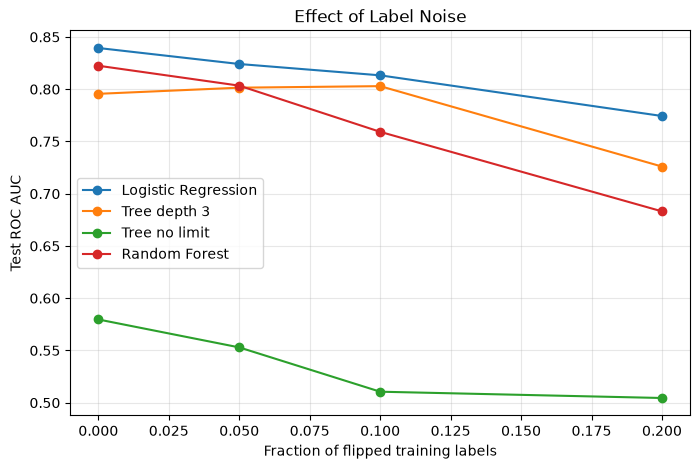

In [27]:
def flip_labels(y, frac, rng):
    """Randomly flip `frac` of the labels (0->1, 1->0)."""
    y_noisy = y.to_numpy().copy()
    n_flip = int(round(frac * len(y_noisy)))
    idx = rng.choice(len(y_noisy), n_flip, replace=False)
    y_noisy[idx] = 1 - y_noisy[idx]
    return pd.Series(y_noisy, index=y.index)

def get_models():
    # har dafa naye (fresh) models
    return {
        "Logistic Regression": LogisticRegression(random_state=SEED, max_iter=1000),
        "Tree depth 3":        DecisionTreeClassifier(max_depth=3, random_state=SEED),
        "Tree no limit":       DecisionTreeClassifier(random_state=SEED),
        "Random Forest":       RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED),
    }

def test_auc(name, model, Xtr_, Xte_, y_fit):
    model.fit(Xtr_, y_fit)
    return roc_auc_score(y_test, model.predict_proba(Xte_)[:, 1])

label_results = {}
for frac in [0, 0.05, 0.10, 0.20]:
    reps = 1 if frac == 0 else 5
    scores = {name: [] for name in get_models()}
    for r in range(reps):
        rng = np.random.default_rng(SEED + r)
        y_noisy = flip_labels(y_train, frac, rng) if frac > 0 else y_train
        for name, model in get_models().items():
            if name == "Logistic Regression":
                scores[name].append(test_auc(name, model, X_train_s, X_test_s, y_noisy))
            else:
                scores[name].append(test_auc(name, model, X_train, X_test, y_noisy))
    label_results[frac] = {k: np.mean(v) for k, v in scores.items()}

label_table = pd.DataFrame(label_results).T
label_table.index.name = "Label noise"
display(label_table.round(4))

label_table.plot(marker="o", figsize=(8, 5))
plt.xlabel("Fraction of flipped training labels")
plt.ylabel("Test ROC AUC")
plt.title("Effect of Label Noise")
plt.grid(alpha=0.3)
plt.show()

,Logistic Regression,Tree depth 3,Tree no limit,Random Forest
Feature noise level,,,,
0.0,0.8394,0.7956,0.5797,0.8224
0.5,0.8337,0.7995,0.5608,0.8140
1.0,0.8098,0.7610,0.5283,0.7870
2.0,0.7695,0.6942,0.5309,0.7406


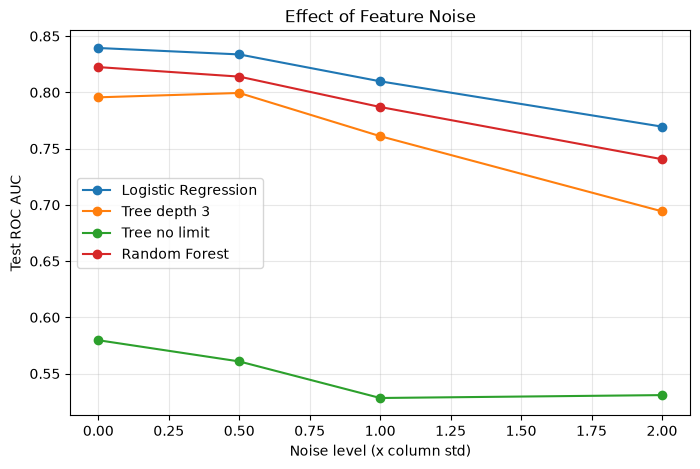

In [28]:
noise_cols = ["age", "avg_glucose_level", "bmi"]

feat_results = {}
for level in [0, 0.5, 1, 2]:
    scores = {name: [] for name in get_models()}
    for r in range(5):
        rng = np.random.default_rng(SEED + r)
        X_noisy = X_train.copy()
        for c in noise_cols:
            X_noisy[c] = X_noisy[c] + rng.normal(size=len(X_noisy)) * X_train[c].std() * level
        sc_n = StandardScaler()
        Xn_s = pd.DataFrame(sc_n.fit_transform(X_noisy), columns=X_noisy.columns, index=X_noisy.index)
        Xte_s_n = pd.DataFrame(sc_n.transform(X_test), columns=X_test.columns, index=X_test.index)

        for name, model in get_models().items():
            if name == "Logistic Regression":
                scores[name].append(test_auc(name, model, Xn_s, Xte_s_n, y_train))
            else:
                scores[name].append(test_auc(name, model, X_noisy, X_test, y_train))
    feat_results[level] = {k: np.mean(v) for k, v in scores.items()}

feat_table = pd.DataFrame(feat_results).T
feat_table.index.name = "Feature noise level"
display(feat_table.round(4))

feat_table.plot(marker="o", figsize=(8, 5))
plt.xlabel("Noise level (x column std)")
plt.ylabel("Test ROC AUC")
plt.title("Effect of Feature Noise")
plt.grid(alpha=0.3)
plt.show()

In [29]:
out = {}
for r in range(3):
    rng = np.random.default_rng(SEED + r)
    y_noisy = flip_labels(y_train, 0.10, rng)

    for name, make, Xtr_, Xte_ in [
        ("Logistic Regression", make_lr, X_train_s, X_test_s),
        ("Random Forest",       make_rf, X_train,   X_test),
    ]:
        for method in ["No SMOTE", "SMOTE"]:
            if method == "SMOTE":
                Xr, yr = SMOTE(random_state=SEED).fit_resample(Xtr_, y_noisy)   # noise ke BAAD
            else:
                Xr, yr = Xtr_, y_noisy
            model = make().fit(Xr, yr)
            p = model.predict_proba(Xte_)[:, 1]
            out.setdefault((name, method), []).append(
                (roc_auc_score(y_test, p), average_precision_score(y_test, p)))

smote_noise = pd.DataFrame(
    {k: np.mean(v, axis=0) for k, v in out.items()}, index=["ROC AUC", "PR AUC"]
).T.round(4)
smote_noise

ROC AUC  PR AUC
Logistic Regression No SMOTE   0.8140  0.2174
                    SMOTE      0.8158  0.2259
Random Forest       No SMOTE   0.7482  0.1543
                    SMOTE      0.6152  0.0834

**Answer (a):**
Random Forest is the most damaged by label noise. At 20% noise its ROC AUC fell from 0.8224 to 0.6831 (a drop of 0.139). The most stable are Logistic Regression (0.8394 to 0.7743, a drop of 0.065) and the depth-3 tree (0.7956 to 0.7260, a drop of 0.070). The tree with no limit is already near random (0.5797 to 0.5045), so it has almost nothing left to lose, and it is not useful even without noise.
This links to Part 2: flexible models (a full tree, a forest of deep trees) have low bias and high variance, so they memorize the wrong labels. Simple models (Logistic Regression, depth 3) have high bias and low variance, so they cannot memorize single wrong labels and only follow the main trend.

**Answer (b):**
They hurt by a similar amount, but label noise is slightly worse overall. At the highest levels (label noise 20% and feature noise level 2) the average drop for Logistic Regression, depth-3 tree and Random Forest is about 0.091 for label noise and 0.084 for feature noise. For Random Forest label noise is clearly worse (0.6831 vs 0.7406). For the depth-3 tree feature noise is worse (0.6942 vs 0.7260).
Reason: wrong labels teach the model wrong answers, and flexible models memorize them. Feature noise only blurs some inputs, and the other columns (like hypertension and heart disease) stay clean.

**Answer (c):**
With 10% noisy labels, SMOTE did almost nothing to Logistic Regression (ROC AUC 0.8140 to 0.8158, PR AUC 0.2174 to 0.2259). But it badly hurt Random Forest: ROC AUC fell from 0.7482 to 0.5967 and PR AUC from 0.1543 to 0.0607, which is almost no better than random.
Why SMOTE amplifies label noise: flipping 10% of labels turns about 390 healthy patients into fake "stroke" patients, while only about 20 real strokes get flipped. So the stroke class becomes mostly wrong (about 570 stroke labels, but only about 180 are real). SMOTE then makes many new synthetic patients between these points, which spreads the wrong labels into even more rows. A Random Forest memorizes all of them, so it learns a false pattern.

Part 6: Final Decision aur Executive Summary

In [30]:
def summarize(pred, label):
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Patients flagged": int(pred.sum()),
        "False alarms (FP)": int(fp),
        "Missed strokes (FN)": int(fn),
    }

pred_default = (test_p >= 0.5).astype(int)          # default threshold
pred_final   = (test_p >= chosen_thr).astype(int)   # train se chuna hua threshold

final_table = pd.DataFrame({
    "Default threshold (0.5)": summarize(pred_default, "default"),
    f"Chosen threshold ({chosen_thr:.4f})": summarize(pred_final, "final"),
}).T
final_table.round(4)

,Precision,Recall,F1,Patients flagged,False alarms (FP),Missed strokes (FN)
Default threshold (0.5),1.0000,0.02,0.0392,1.0,0.0,49.0
Chosen threshold (0.0509),0.1349,0.82,0.2316,304.0,263.0,9.0


**Executive Summary**
I chose Logistic Regression (on scaled data) with a lowered decision threshold of 0.0509 to screen patients for stroke. The threshold was picked using only the training data (out-of-fold probabilities), as the highest value giving at least 80% recall.
On the test set, this catches 41 of 50 strokes (recall 0.82) and misses only 9, compared with 49 missed at the default 0.5 threshold (recall 0.02). Precision is 0.135 and F1 is 0.232.
The price is 263 false alarms: 304 patients are flagged, but about 7 in 8 of them are healthy. For a screening test this is acceptable, because a missed stroke is much worse than an extra check-up.
I avoided data leakage by learning the median, the scaler and the threshold from the training set only, and by never resampling or touching the test set. I also showed that applying SMOTE before the split gives fake, over-optimistic results.
Limitation: the test set has only 50 stroke patients, so one patient changes recall by 2%, and the threshold may not generalize exactly. The threshold also depends on the recall target we picked, and the model has low precision.

**(a) Most surprising result:**
Logistic Regression had a recall of only 0.02 and a high accuracy (0.952), but its ROC AUC was 0.84. Just lowering the threshold raised recall to 0.82. I was also surprised that SMOTE made Random Forest worse (ROC AUC 0.7668) and that the wrong-order SMOTE gave a fake ROC AUC of 0.98.

**(b) With one more hour:**
I would repeat the split with many random seeds (or use repeated cross-validation) and give confidence intervals, because there are only 50 stroke patients in the test set. I would also try a Gradient Boosting model, calibrate the probabilities, and choose the threshold using the real cost of a missed stroke versus a false alarm.